Welcome to **Module 3** of Course 3: Advanced NLP — Large Language Models!

In **[Module 1](https://www.kaggle.com/code/arminnorouzig/advanced-nlp-module-1-the-attention-revolution)** we built self-attention, and in **[Module 2](https://www.kaggle.com/code/arminnorouzig/advanced-nlp-module-2-positional-encoding)** we gave it a sense of word order with positional encoding. We now have two powerful building blocks. In this module, we combine them — together with a Feed-Forward Network and residual connections — into the two core reusable units of the Transformer: the **EncoderLayer** and the **DecoderLayer**. These are the Lego bricks that stack to form the complete model we will assemble in [Module 4](https://www.kaggle.com/code/arminnorouzig/advanced-nlp-module-4-building-the-transformer).

# Introduction

The original Transformer architecture ([*Attention Is All You Need*, Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)) is built around a clean separation of responsibilities:

* The **Encoder** reads the entire input sequence (e.g., a Portuguese sentence) and compresses it into a rich sequence of context vectors. It does not produce output tokens — it just *understands* the input.
* The **Decoder** generates the output sequence one token at a time (e.g., an English word), attending to both what it has generated so far and the encoder's understanding of the source.

Both are built by stacking identical layers. A single **EncoderLayer** contains:
1. Multi-Head Self-Attention
2. Add & Norm (residual connection + layer normalization)
3. Feed-Forward Network
4. Add & Norm again

A single **DecoderLayer** contains those same four steps plus an extra cross-attention block in the middle that lets the decoder look at the encoder's output.

Let's build each one from scratch as a reusable `tf.keras.layers.Layer`.

# The Encoder Layer

Every EncoderLayer applies the same four operations in sequence. The key design principle is the **residual connection**: after each sub-layer (attention or FFN), we *add* the sub-layer's output back to its input before normalizing. This creates a shortcut that lets gradients flow cleanly through deep stacks — the same idea that made ResNets so powerful in computer vision.

The three operations and their formulas:

**1. Multi-Head Self-Attention**

$$\text{MultiHead}(Q,K,V) = \text{Concat}(\text{head}_1,\ldots,\text{head}_h)\,W^O$$

$$\text{head}_i = \text{Attention}(QW_i^Q,\, KW_i^K,\, VW_i^V)$$

Running multiple heads in parallel allows the model to simultaneously learn different types of relationships — some heads might specialize in syntactic structure, others in semantic similarity, others in co-reference.

**2. Add & Norm (Residual + Layer Normalization)**

$$\text{output}_1 = \text{LayerNorm}(x + \text{MultiHeadAttention}(x))$$

The `+` is the residual connection. `LayerNorm` normalizes each token's representation independently across the feature dimension, keeping activations stable as the network grows deeper.

**3. Position-Wise Feed-Forward Network (FFN)**

$$\text{FFN}(x) = \max(0,\, xW_1 + b_1)\,W_2 + b_2$$

Two dense layers with a ReLU in between, applied **independently to each position**. The inner dimension `dff` is typically 4× the model dimension. This is where most of the model's capacity to learn complex transformations lives.

**4. Add & Norm again**

$$\text{output}_2 = \text{LayerNorm}(\text{output}_1 + \text{FFN}(\text{output}_1))$$

```mermaid
graph TD
    A["Input<br/>(batch, seq_len, d_model)"] --> B["Multi-Head Self-Attention<br/>(Q=K=V=input)"]
    A --> R1[" "]
    B --> N1["Add & Norm<br/>(residual + LayerNorm)"]
    R1 --> N1
    N1 --> C["Feed-Forward Network<br/>Dense(dff, ReLU) → Dense(d_model)"]
    N1 --> R2[" "]
    C --> N2["Add & Norm<br/>(residual + LayerNorm)"]
    R2 --> N2
    N2 --> F["EncoderLayer Output<br/>(batch, seq_len, d_model)"]
```

Notice that the **output shape is identical to the input shape** — `(batch, seq_len, d_model)`. This is what allows us to stack `N` identical EncoderLayers: the output of layer $k$ feeds directly into layer $k+1$ without any shape changes.

## Implementing the EncoderLayer

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, Model

class EncoderLayer(tf.keras.layers.Layer):
    """
    One Transformer Encoder layer.

    Sub-layers (in order):
        1. Multi-Head Self-Attention
        2. Add & Norm
        3. Position-Wise Feed-Forward Network
        4. Add & Norm
    """

    def __init__(self, d_model, num_heads, dff, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.d_model      = d_model
        self.num_heads    = num_heads
        self.dff          = dff
        self.dropout_rate = dropout_rate

        # Sub-layer 1: Multi-Head Self-Attention
        self.mha = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=d_model // num_heads,
            name="self_attention"
        )

        # Sub-layer 3: Feed-Forward Network (two dense layers)
        self.ffn_dense1 = layers.Dense(dff, activation='relu', name="ffn_dense1")
        self.ffn_dense2 = layers.Dense(d_model, name="ffn_dense2")

        # Layer normalization (one per Add & Norm step)
        self.norm1 = layers.LayerNormalization(epsilon=1e-6, name="norm1")
        self.norm2 = layers.LayerNormalization(epsilon=1e-6, name="norm2")

        # Dropout (applied before adding the residual)
        self.dropout1 = layers.Dropout(dropout_rate)
        self.dropout2 = layers.Dropout(dropout_rate)

    def call(self, x, training=False, mask=None):
        # --- Sub-layer 1 + Add & Norm ---
        attn_output = self.mha(x, x, x, attention_mask=mask)          # self-attention
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.norm1(x + attn_output)                            # residual + norm

        # --- Sub-layer 3 (FFN) + Add & Norm ---
        ffn_output = self.ffn_dense2(self.ffn_dense1(out1))           # FFN
        ffn_output = self.dropout2(ffn_output, training=training)
        out2 = self.norm2(out1 + ffn_output)                          # residual + norm

        return out2   # shape: (batch, seq_len, d_model) — same as input

    def get_config(self):
        config = super().get_config()
        config.update({
            "d_model": self.d_model, "num_heads": self.num_heads,
            "dff": self.dff, "dropout_rate": self.dropout_rate
        })
        return config


# ── Wrap in a functional Keras model so model.summary() shows full details ──
D_MODEL = 32
NUM_HEADS = 2
DFF = 64
SEQ_LEN = 60

enc_input = layers.Input(shape=(SEQ_LEN, D_MODEL), name="encoder_input")
enc_output = EncoderLayer(D_MODEL, NUM_HEADS, DFF, name="encoder_layer")(enc_input)
encoder_layer_model = Model(inputs=enc_input, outputs=enc_output, name="EncoderLayer_Model")

print("=== EncoderLayer Model Summary ===")
encoder_layer_model.summary()

2026-10-25 08:26:22.669607: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792916782.852339      16 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792916782.906310      16 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792916783.334961      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792916783.335002      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792916783.335004      16 computation_placer.cc:177] computation placer alr

=== EncoderLayer Model Summary ===


2026-10-25 08:26:49.492308: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "EncoderLayer_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 60, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_layer (EncoderLayer)    │ (None, 60, 32)         │         8,544 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,544 (33.38 KB)

 Trainable params: 8,544 (33.38 KB)

 Non-trainable params: 0 (0.00 B)

**Code Explanation:**
* **`MultiHeadAttention(num_heads=2, key_dim=16)`**: With `d_model=32` and 2 heads, each head works in a 16-dimensional Q/K/V space. The layer internally concatenates the outputs of all heads and projects back to `d_model` — exactly the $W^O$ matrix from the formula. We pass `(x, x, x)` as `(query, key, value)` to implement *self*-attention.
* **`ffn_dense1` / `ffn_dense2`**: Two separate `Dense` layers rather than a single combined one. The first expands to `dff=64` dimensions with ReLU activation — giving the model a wider "thinking space" per position. The second projects back to `d_model=32`, keeping the output shape stable for the next layer.
* **`LayerNormalization(epsilon=1e-6)`**: Normalizes each token's vector independently across the `d_model` feature dimension. `epsilon=1e-6` prevents division by zero on near-zero variance. Unlike `BatchNormalization` (which normalizes across the batch), `LayerNorm` works on a single example at a time — essential for variable-length sequences.
* **Residual connections (`x + attn_output`, `out1 + ffn_output`)**: The `+` operator is the residual shortcut. Gradients can flow directly through the addition without passing through the sub-layer weights, making it much easier to train deep stacks without vanishing gradients — the same principle that made ResNets work in computer vision.
* **`get_config()`**: Required for Keras serialization. Without it, saving/loading the model would fail because Keras wouldn't know how to reconstruct the custom layer from its config.

# The Decoder Layer

The DecoderLayer is structurally similar to the EncoderLayer but adds a crucial second attention block. It needs to do two things at once: attend to what it has already generated, and attend to the encoder's understanding of the source sentence.

**The three attention steps:**

1. **Masked Self-Attention**: The decoder attends to its own previously generated tokens. The word "masked" means we apply a **look-ahead mask** — a triangular matrix that prevents position $t$ from seeing positions $t+1, t+2, \ldots$ during training. Without this mask, the model could simply copy the target sequence rather than learning to predict it.

2. **Cross-Attention** (Encoder-Decoder Attention): The decoder's Query vectors come from the previous step's output; the Key and Value vectors come from the **encoder output**. This is the bridge between the two halves — it's how the decoder "reads" the source sentence while generating each output word.

3. **Feed-Forward Network**: Same as in the EncoderLayer — applied independently to each position after attention.

Each step is followed by an Add & Norm residual connection:

$$\text{out}_1 = \text{LayerNorm}(x + \text{MaskedMHA}(x))$$
$$\text{out}_2 = \text{LayerNorm}(\text{out}_1 + \text{CrossMHA}(\text{out}_1,\, \text{enc\_output}))$$
$$\text{out}_3 = \text{LayerNorm}(\text{out}_2 + \text{FFN}(\text{out}_2))$$

```mermaid
graph TD
    T["Target Input<br/>(batch, tgt_len, d_model)"] --> B["Masked Multi-Head Self-Attention<br/>(look-ahead mask applied)"]
    T --> R1[" "]
    B --> N1["Add & Norm"]
    R1 --> N1
    N1 --> C["Cross-Attention<br/>(Q=decoder, K=V=Encoder Output)"]
    ENC["Encoder Output<br/>(batch, src_len, d_model)"] --> C
    N1 --> R2[" "]
    C --> N2["Add & Norm"]
    R2 --> N2
    N2 --> D["Feed-Forward Network<br/>Dense(dff, ReLU) → Dense(d_model)"]
    N2 --> R3[" "]
    D --> N3["Add & Norm"]
    R3 --> N3
    N3 --> F["DecoderLayer Output<br/>(batch, tgt_len, d_model)"]
```

The key difference from the EncoderLayer: the **Encoder Output** enters from the side as the Key and Value for cross-attention. This lets every decoder position look at every encoder position — the mechanism that translates source meaning into target words.

## Implementing the DecoderLayer

In [2]:
class DecoderLayer(tf.keras.layers.Layer):
    """
    One Transformer Decoder layer.

    Sub-layers (in order):
        1. Masked Multi-Head Self-Attention  (look-ahead mask)
        2. Add & Norm
        3. Cross-Attention  (Q=decoder, K=V=encoder output)
        4. Add & Norm
        5. Position-Wise Feed-Forward Network
        6. Add & Norm
    """

    def __init__(self, d_model, num_heads, dff, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.d_model      = d_model
        self.num_heads    = num_heads
        self.dff          = dff
        self.dropout_rate = dropout_rate

        # Sub-layer 1: Masked self-attention (target attends to itself)
        self.mha1 = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=d_model // num_heads,
            name="masked_self_attention"
        )

        # Sub-layer 3: Cross-attention (decoder queries the encoder output)
        self.mha2 = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=d_model // num_heads,
            name="cross_attention"
        )

        # Sub-layer 5: Feed-Forward Network
        self.ffn_dense1 = layers.Dense(dff, activation='relu', name="ffn_dense1")
        self.ffn_dense2 = layers.Dense(d_model, name="ffn_dense2")

        # Layer normalization (one per Add & Norm step — three total)
        self.norm1 = layers.LayerNormalization(epsilon=1e-6, name="norm1")
        self.norm2 = layers.LayerNormalization(epsilon=1e-6, name="norm2")
        self.norm3 = layers.LayerNormalization(epsilon=1e-6, name="norm3")

        self.dropout1 = layers.Dropout(dropout_rate)
        self.dropout2 = layers.Dropout(dropout_rate)
        self.dropout3 = layers.Dropout(dropout_rate)

    def call(self, x, enc_output, training=False,
             look_ahead_mask=None, padding_mask=None):
        """
        Args:
            x              : target sequence embeddings  (batch, tgt_len, d_model)
            enc_output     : encoder output             (batch, src_len, d_model)
            look_ahead_mask: causal mask for self-attention  (prevents future peeking)
            padding_mask   : padding mask for cross-attention (ignores <PAD> tokens)
        """
        # --- Sub-layer 1: Masked Self-Attention + Add & Norm ---
        attn1 = self.mha1(x, x, x, attention_mask=look_ahead_mask)       # self-attention
        attn1 = self.dropout1(attn1, training=training)
        out1  = self.norm1(x + attn1)

        # --- Sub-layer 3: Cross-Attention + Add & Norm ---
        # Q comes from the decoder (out1); K and V come from the encoder
        attn2 = self.mha2(out1, enc_output, enc_output,
                          attention_mask=padding_mask)                     # cross-attention
        attn2 = self.dropout2(attn2, training=training)
        out2  = self.norm2(out1 + attn2)

        # --- Sub-layer 5: FFN + Add & Norm ---
        ffn_out = self.ffn_dense2(self.ffn_dense1(out2))
        ffn_out = self.dropout3(ffn_out, training=training)
        out3    = self.norm3(out2 + ffn_out)

        return out3   # shape: (batch, tgt_len, d_model)

    def get_config(self):
        config = super().get_config()
        config.update({
            "d_model": self.d_model, "num_heads": self.num_heads,
            "dff": self.dff, "dropout_rate": self.dropout_rate
        })
        return config


# ── Wrap in a functional model to show model.summary() ──
tgt_input  = layers.Input(shape=(SEQ_LEN, D_MODEL), name="target_input")
src_input  = layers.Input(shape=(SEQ_LEN, D_MODEL), name="encoder_output")
dec_layer  = DecoderLayer(D_MODEL, NUM_HEADS, DFF, name="decoder_layer")
dec_out    = dec_layer(tgt_input, src_input)
decoder_layer_model = Model(
    inputs=[tgt_input, src_input], outputs=dec_out,
    name="DecoderLayer_Model"
)

print("=== DecoderLayer Model Summary ===")
decoder_layer_model.summary()

=== DecoderLayer Model Summary ===


Model: "DecoderLayer_Model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ target_input        │ (None, 60, 32)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_output      │ (None, 60, 32)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_layer       │ (None, 60, 32)    │     12,832 │ target_input[0][… │
│ (DecoderLayer)      │                   │            │ encoder_output[0… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 12,832 (50.12 KB)

 Trainable params: 12,832 (50.12 KB)

 Non-trainable params: 0 (0.00 B)

**Code Explanation:**
* **Two separate `MultiHeadAttention` layers (`mha1`, `mha2`)**: The first is masked self-attention — queries, keys, and values all come from the target sequence `x`. The second is cross-attention — the query comes from `out1` (the decoder's representation so far), but the keys and values come from `enc_output` (the encoder's understanding of the source). This asymmetry is what makes the decoder a bridge between the two languages.
* **`mha1(x, x, x, attention_mask=look_ahead_mask)`**: The look-ahead mask is a causal (triangular) mask. Position $t$ can only attend to positions $0 \ldots t$ — not to future positions. Without this mask, the model could learn a trivial "cheat" during training: simply copying the target from the future positions it is not supposed to see.
* **`mha2(out1, enc_output, enc_output, attention_mask=padding_mask)`**: Notice the argument order: `(query, key, value)`. The query is the current decoder state `out1`; the key and value are both the encoder output. This allows every decoder position to attend to every encoder position — the cross-attention bridge.
* **Three normalization layers vs. two**: The DecoderLayer has three Add & Norm steps compared to two in the EncoderLayer — one after each of the three sub-layers. The model summary shows three separate `LayerNormalization` entries.
* **Two inputs to the functional model**: `Model(inputs=[tgt_input, src_input], ...)` — we pass both the target sequence and the encoder output as separate inputs. This is necessary for `model.summary()` to trace the full computation graph.

# Verifying Both Layers with Dummy Tensors

Before training, let's confirm both layers produce the correct output shapes with a simple forward pass using dummy (zero) tensors.

In [3]:
import numpy as np

BATCH = 2

# Dummy encoder input: (batch=2, seq_len=60, d_model=32)
dummy_src = tf.zeros((BATCH, SEQ_LEN, D_MODEL))

# EncoderLayer forward pass
enc_layer = EncoderLayer(D_MODEL, NUM_HEADS, DFF)
enc_out   = enc_layer(dummy_src, training=False)
print(f"EncoderLayer  input  shape: {dummy_src.shape}")
print(f"EncoderLayer  output shape: {enc_out.shape}")
print(f"Shape preserved? {dummy_src.shape == enc_out.shape}")

print()

# Dummy decoder target: (batch=2, tgt_len=60, d_model=32)
dummy_tgt = tf.zeros((BATCH, SEQ_LEN, D_MODEL))

# DecoderLayer forward pass — takes both target and encoder output
dec_layer = DecoderLayer(D_MODEL, NUM_HEADS, DFF)
dec_out   = dec_layer(dummy_tgt, enc_out, training=False)
print(f"DecoderLayer  target shape: {dummy_tgt.shape}")
print(f"DecoderLayer  enc_out shape: {enc_out.shape}")
print(f"DecoderLayer  output shape: {dec_out.shape}")

EncoderLayer  input  shape: (2, 60, 32)
EncoderLayer  output shape: (2, 60, 32)
Shape preserved? True

DecoderLayer  target shape: (2, 60, 32)
DecoderLayer  enc_out shape: (2, 60, 32)
DecoderLayer  output shape: (2, 60, 32)


**Code Explanation:**
* **`tf.zeros((BATCH, SEQ_LEN, D_MODEL))`**: A tensor of all zeros with the expected input shape. Zero tensors are ideal for shape checks — any numerical error in the forward pass (e.g., a broadcasting mismatch) will raise an exception immediately, without needing real data.
* **Shape preservation**: Both layers return tensors with the same shape as their primary input. This is the key property that allows us to stack them: `EncoderLayer(EncoderLayer(x))` is valid because both layers produce `(batch, seq_len, d_model)`. In Module 4, we will stack `N` EncoderLayers and `N` DecoderLayers into complete Encoder and Decoder stacks.

# Training a Sample Encoder-Only Classifier (Illustration Only)

To prove the `EncoderLayer` trains correctly end-to-end, we build a minimal encoder-only classifier and run it on 200 samples from the Sentiment Dataset.

> **Important:** This tiny model (`d_model=32`, `num_heads=2`, `dff=64`, 200 samples, 5 epochs) is for illustration only. Its purpose is to confirm that gradients flow correctly through the EncoderLayer and that the loss decreases — not to achieve production-level accuracy.

In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf

# 1. Find local dataset files
input_dir = Path("/kaggle/input")

pairs = [
    (path, path.parent / "rt-polarity.neg")
    for path in sorted(input_dir.rglob("rt-polarity.pos"))
    if (path.parent / "rt-polarity.neg").is_file()
]

if len(pairs) != 1:
    raise FileNotFoundError(
        "Attach the polarity dataset using Add Input. "
        "Expected one folder containing rt-polarity.pos "
        "and rt-polarity.neg."
    )

positive_file, negative_file = pairs[0]

def read_lines(path):
    with open(path, "r", encoding="latin-1") as file:
        return [
            line.strip()
            for line in file
            if line.strip()
        ]

positives = read_lines(positive_file)
negatives = read_lines(negative_file)

# 2. Create and shuffle DataFrame
df = pd.DataFrame({
    "text": positives + negatives,
    "label": [1] * len(positives) + [0] * len(negatives)
})

df = df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# 3. Build vocabulary
VOCAB_SIZE = 5000
MAX_LEN = 60

vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_mode="int",
    output_sequence_length=MAX_LEN
)

vectorizer.adapt(
    tf.constant(df["text"].tolist(), dtype=tf.string)
)

# 4. Prepare 200 samples
df_tiny = df.head(200).reset_index(drop=True)

X_tiny = vectorizer(
    tf.constant(df_tiny["text"].tolist(), dtype=tf.string)
).numpy()

Y_tiny = df_tiny["label"].to_numpy(dtype=np.float32)

print("Full dataset    :", len(df))
print("Vocabulary size :", vectorizer.vocabulary_size())
print("X shape         :", X_tiny.shape)
print("Y shape         :", Y_tiny.shape)

Full dataset    : 10662
Vocabulary size : 5000
X shape         : (200, 60)
Y shape         : (200,)


=== Tiny Encoder-Only Classifier ===


Model: "EncoderOnly_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ token_ids (InputLayer)          │ (None, 60)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 60, 32)         │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ positional_encoding             │ (None, 60, 32)         │             0 │
│ (PositionalEncoding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_layer (EncoderLayer)    │ (None, 60, 32)         │         8,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequence_avg                    │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sentiment_output (Dense)        │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 168,577 (658.50 KB)

 Trainable params: 168,577 (658.50 KB)

 Non-trainable params: 0 (0.00 B)


Starting tiny training run (200 samples, 5 epochs)...
Epoch 1/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.4868 - loss: 0.8030 - val_accuracy: 0.5750 - val_loss: 0.6922
Epoch 2/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5595 - loss: 0.6770 - val_accuracy: 0.4250 - val_loss: 0.7252
Epoch 3/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5105 - loss: 0.6991 - val_accuracy: 0.5750 - val_loss: 0.6824
Epoch 4/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5449 - loss: 0.6848 - val_accuracy: 0.5750 - val_loss: 0.6829
Epoch 5/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5998 - loss: 0.6721 - val_accuracy: 0.4250 - val_loss: 0.7071


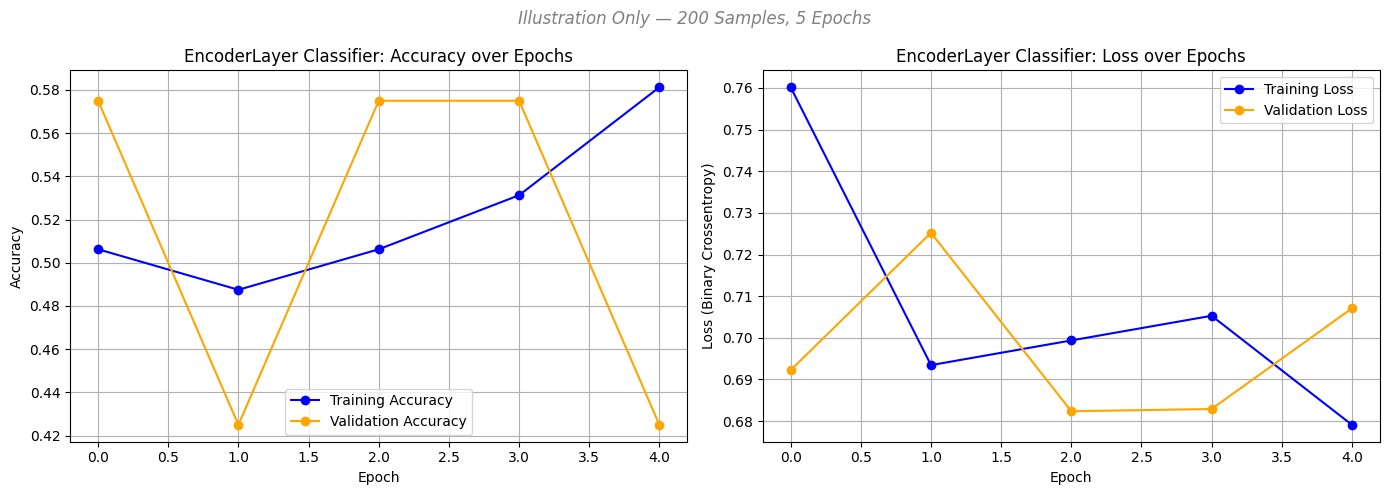


Final training loss:     0.6791
Final training accuracy: 0.5813
Key observation: loss decreased — the EncoderLayer trains correctly!


In [5]:
import matplotlib.pyplot as plt

# Build encoder-only classifier:
#   Embedding → PositionalEncoding → EncoderLayer → GlobalAvgPool → Dense

# Re-use PositionalEncoding from Module 2
class PositionalEncoding(tf.keras.layers.Layer):
    def __init__(self, max_len, d_model, **kwargs):
        super().__init__(**kwargs)
        self.max_len = max_len
        self.d_model = d_model
        positions   = np.arange(max_len)[:, np.newaxis]
        i_indices   = np.arange(d_model // 2)[np.newaxis, :]
        angles      = positions / np.power(10000.0, (2 * i_indices) / d_model)
        pe          = np.zeros((max_len, d_model))
        pe[:, 0::2] = np.sin(angles)
        pe[:, 1::2] = np.cos(angles)
        self.pe     = tf.cast(pe[np.newaxis, :, :], tf.float32)
    def call(self, x):
        return x + self.pe[:, :tf.shape(x)[1], :]
    def get_config(self):
        c = super().get_config()
        c.update({"max_len": self.max_len, "d_model": self.d_model})
        return c


def build_encoder_classifier(vocab_size, max_len, d_model, num_heads, dff):
    """Encoder-only binary sentiment classifier."""
    inputs = layers.Input(shape=(max_len,), dtype=tf.int32, name="token_ids")
    x = layers.Embedding(vocab_size, d_model, name="embedding")(inputs)
    x = PositionalEncoding(max_len, d_model, name="positional_encoding")(x)
    x = EncoderLayer(d_model, num_heads, dff, name="encoder_layer")(x)
    x = layers.GlobalAveragePooling1D(name="sequence_avg")(x)
    outputs = layers.Dense(1, activation='sigmoid', name="sentiment_output")(x)
    return Model(inputs=inputs, outputs=outputs, name="EncoderOnly_Classifier")


tiny_model = build_encoder_classifier(VOCAB_SIZE, MAX_LEN, D_MODEL, NUM_HEADS, DFF)
print("=== Tiny Encoder-Only Classifier ===")
tiny_model.summary()

tiny_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("\nStarting tiny training run (200 samples, 5 epochs)...")
history = tiny_model.fit(
    X_tiny, Y_tiny,
    epochs=5,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

# Learning curves — Course 2 style
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history['accuracy'],     label='Training Accuracy',   color='blue',   marker='o')
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange', marker='o')
ax1.set_title('EncoderLayer Classifier: Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

ax2.plot(history.history['loss'],     label='Training Loss',   color='blue',   marker='o')
ax2.plot(history.history['val_loss'], label='Validation Loss', color='orange', marker='o')
ax2.set_title('EncoderLayer Classifier: Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss (Binary Crossentropy)')
ax2.legend()
ax2.grid(True)

plt.suptitle('Illustration Only — 200 Samples, 5 Epochs', fontstyle='italic', color='gray')
plt.tight_layout()
plt.show()

print(f"\nFinal training loss:     {history.history['loss'][-1]:.4f}")
print(f"Final training accuracy: {history.history['accuracy'][-1]:.4f}")
print("Key observation: loss decreased — the EncoderLayer trains correctly!")

**Code Explanation:**
* **`build_encoder_classifier`**: The pipeline `Embedding → PositionalEncoding → EncoderLayer → GlobalAveragePooling1D → Dense` is the encoder-only Transformer pattern — the same architecture used by BERT-style models. The `GlobalAveragePooling1D` collapses the `(batch, seq_len, d_model)` tensor into a `(batch, d_model)` summary vector, which the final `Dense` then classifies.
* **`PositionalEncoding` redefined here**: We include a compact copy so this module is self-contained and runnable without importing from Module 2. In a production codebase you would share this as a common utility.
* **`tiny_model.summary()`**: Notice the `encoder_layer` entry in the summary. Because `EncoderLayer` is a subclassed layer, Keras shows its total parameter count rather than expanding its internal sub-layers. The total trainable parameters should be small — confirming the `d_model=32`, `dff=64` dimensions are indeed tiny.
* **What the curves tell us**: The training loss decreasing confirms that gradients flow correctly through the residual connections, layer normalizations, multi-head attention, and feed-forward layers — the entire EncoderLayer stack is differentiable and optimizable. The absolute accuracy values on 200 samples are not meaningful.

# Conclusion & Next Steps

In this module, we built the two core reusable units of the Transformer from scratch. The `EncoderLayer` combines self-attention, residual connections, layer normalization, and a feed-forward network into a single composable block that preserves input shape — meaning we can stack as many as we need. The `DecoderLayer` extends this with a second cross-attention block that reads the encoder's output, creating the bridge between source understanding and target generation.

Both layers are now tested, shape-verified, and confirmed to train correctly. We also established the key architectural pattern we will carry into Module 4:

> **Embedding → Positional Encoding → Stack of Encoder/Decoder Layers → Output projection**

In **[Module 4: Building the Transformer](https://www.kaggle.com/code/arminnorouzig/advanced-nlp-building-transformer)**, we will stack these layers into complete `Encoder` and `Decoder` classes, wire them together with masking, and assemble the full end-to-end `Transformer` model ready to train on real translation data.

<script type="module">
  import mermaid from 'https://cdn.jsdelivr.net/npm/mermaid@10/dist/mermaid.esm.min.mjs';

  // Find ALL generic code blocks
  const blocks = document.querySelectorAll('pre code');

  blocks.forEach((block) => {
      let text = block.textContent.trim();
      let isMermaid = false;
      let diagramCode = text;

      // Case 1: Check if the element or its parent has a mermaid class
      const hasMermaidClass = Array.from(block.classList).some(cls => cls.includes('mermaid')) || 
                             (block.parentElement && Array.from(block.parentElement.classList).some(cls => cls.includes('mermaid')));

      if (hasMermaidClass) {
          isMermaid = true;
      } 
      // Case 2: Check if the text literally starts with the word "mermaid"
      else if (text.startsWith('mermaid')) {
          isMermaid = true;
          // Strip out the word "mermaid" and any leading whitespace/newlines
          diagramCode = text.replace(/^mermaid\s*/i, '');
      }

      if (isMermaid) {
          // Create a proper div for Mermaid
          const div = document.createElement('div');
          div.className = 'mermaid';
          div.textContent = diagramCode;

          // Replace the parent <pre> tag with the new div
          const pre = block.parentElement;
          if (pre && pre.tagName === 'PRE') {
              pre.replaceWith(div);
          }
      }
  });

  // Initialize and run the render
  mermaid.initialize({ startOnLoad: false });
  await mermaid.run();
</script>
